# PS10: Music genre classification with an RNN (GTZAN)
Dataset layout (Kaggle GTZAN): Data/genres_original/<genre>/*.wav  (10 genres x 100 clips of 30 s)
Each clip is cut into 10 segments of 3 s; each segment becomes a sequence of MFCC frames (130 x 13).

In [1]:
import os

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = "../datasets/gtzan/Data/genres_original"
EPOCHS = 40
SR = 22050
SEGMENTS = 10
N_MFCC = 13
SEG_LEN = SR * 30 // SEGMENTS

['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'] files: 1000


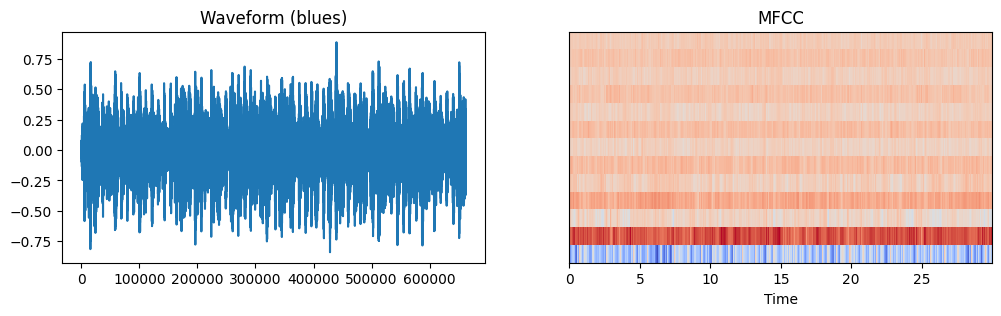

In [2]:
genres = sorted(os.listdir(DATA_DIR))
files, labels = [], []
for label, genre in enumerate(genres):
    for f in sorted(os.listdir(os.path.join(DATA_DIR, genre))):
        files.append(os.path.join(DATA_DIR, genre, f))
        labels.append(label)
print(genres, "files:", len(files))

signal, _ = librosa.load(files[0], sr=SR, duration=30)
mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=N_MFCC)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(signal)
ax[0].set_title(f"Waveform ({genres[labels[0]]})")
librosa.display.specshow(mfcc, sr=SR, x_axis="time", ax=ax[1])
ax[1].set_title("MFCC")
plt.show()

In [3]:
def extract(paths, labels):
    X, y = [], []
    for path, label in zip(paths, labels):
        try:
            signal, _ = librosa.load(path, sr=SR, duration=30)
        except Exception:
            print("Skipping unreadable file:", path)
            continue
        for s in range(SEGMENTS):
            seg = signal[s * SEG_LEN:(s + 1) * SEG_LEN]
            if len(seg) == SEG_LEN:
                X.append(librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC).T)
                y.append(label)
    return np.array(X), np.array(y)


# Split by song so segments of one song never appear in both train and test.
f_train, f_test, l_train, l_test = train_test_split(files, labels, test_size=0.2, stratify=labels, random_state=42)
X_train, y_train = extract(f_train, l_train)
X_test, y_test = extract(f_test, l_test)

mean, std = X_train.mean(axis=(0, 1)), X_train.std(axis=(0, 1))
X_train, X_test = (X_train - mean) / std, (X_test - mean) / std
print("Train:", X_train.shape, " Test:", X_test.shape)

C:\Users\choud\AppData\Local\Temp\ipykernel_50936\328162235.py:5: UserWarning: PySoundFile failed. Trying audioread instead.
  signal, _ = librosa.load(path, sr=SR, duration=30)
C:\23410023\lib\site-packages\librosa\core\audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Skipping unreadable file: ../datasets/gtzan/Data/genres_original\jazz\jazz.00054.wav


Train: (7981, 130, 13)  Test: (2000, 130, 13)


In [4]:
model = keras.Sequential([
    layers.Input(X_train.shape[1:]),
    layers.SimpleRNN(128, return_sequences=True),
    layers.SimpleRNN(64),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(genres), activation="softmax"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 130, 128)       │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,338 (138.04 KB)

 Trainable params: 35,338 (138.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train, y_train, validation_split=0.1, epochs=EPOCHS, batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)], verbose=2)

Epoch 1/40


225/225 - 6s - 29ms/step - accuracy: 0.3312 - loss: 1.8527 - val_accuracy: 0.4518 - val_loss: 1.6088


Epoch 2/40


225/225 - 5s - 21ms/step - accuracy: 0.3459 - loss: 1.8146 - val_accuracy: 0.3780 - val_loss: 1.7389


Epoch 3/40


225/225 - 5s - 21ms/step - accuracy: 0.3599 - loss: 1.7767 - val_accuracy: 0.4330 - val_loss: 1.6283


... (16 outputs left out)

Epoch 12/40


225/225 - 5s - 23ms/step - accuracy: 0.4053 - loss: 1.6433 - val_accuracy: 0.4456 - val_loss: 1.5850


Epoch 13/40


225/225 - 5s - 23ms/step - accuracy: 0.4096 - loss: 1.6364 - val_accuracy: 0.4606 - val_loss: 1.5787


Test accuracy: 0.4155   Test loss: 1.5955


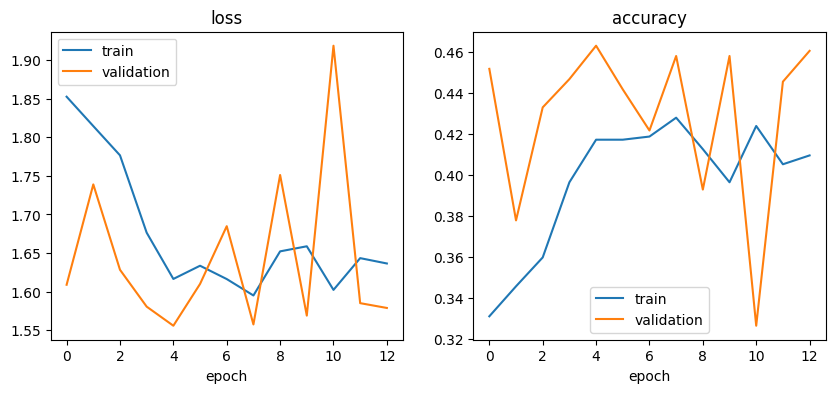

In [6]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.4f}   Test loss: {loss:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()

              precision    recall  f1-score   support

       blues     0.3189    0.5150    0.3939       200
   classical     0.7427    0.7650    0.7537       200
     country     0.3063    0.1700    0.2186       200
       disco     0.1931    0.1400    0.1623       200
      hiphop     0.3813    0.2650    0.3127       200
        jazz     0.3241    0.4100    0.3620       200
       metal     0.4964    0.6850    0.5756       200
         pop     0.4613    0.7450    0.5698       200
      reggae     0.3923    0.3550    0.3727       200
        rock     0.4884    0.1050    0.1728       200

    accuracy                         0.4155      2000
   macro avg     0.4105    0.4155    0.3894      2000
weighted avg     0.4105    0.4155    0.3894      2000



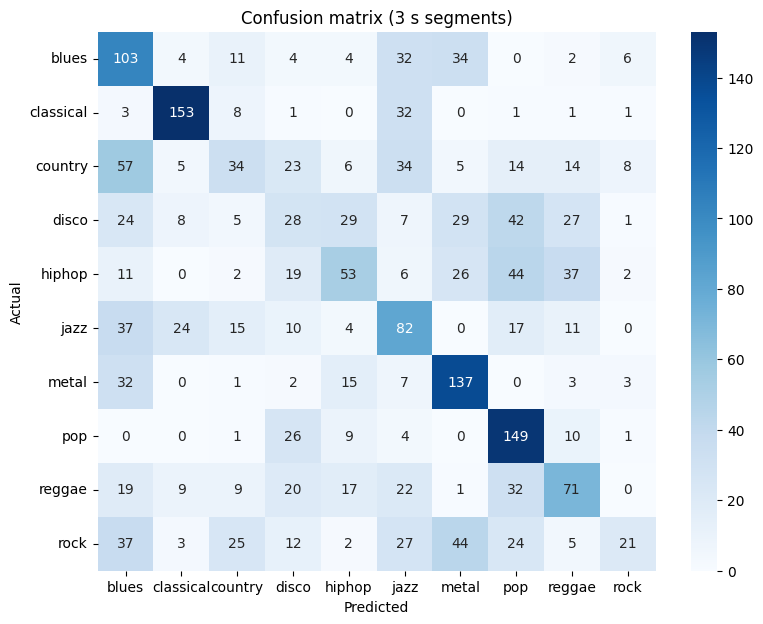

In [7]:
y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=genres, digits=4, zero_division=0))

plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=genres, yticklabels=genres)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (3 s segments)")
plt.show()

In [8]:
def predict_song(path):
    X, _ = extract([path], [0])
    if len(X) == 0:
        return "unreadable", 0.0
    probs = model.predict((X - mean) / std, verbose=0).mean(axis=0)
    return genres[probs.argmax()], probs.max()


for path, label in list(zip(f_test, l_test))[:5]:
    genre, conf = predict_song(path)
    print(f"{os.path.basename(path):20s} actual={genres[label]:10s} predicted={genre:10s} ({conf:.2f})")

classical.00071.wav  actual=classical  predicted=classical  (0.56)
blues.00092.wav      actual=blues      predicted=blues      (0.38)


metal.00070.wav      actual=metal      predicted=jazz       (0.30)
jazz.00035.wav       actual=jazz       predicted=country    (0.25)


blues.00021.wav      actual=blues      predicted=blues      (0.39)
